# Comparación de Arquitecturas YOLO

Se analiza el rendimiento de las distintas arquitecturas YOLO:

- `yolo26m`
- `yolo12m`
- `yolo11m`
- `yolov10m`


## 1. Construcción del dataframe

Se unifican las tres fuentes de resultados:

| Archivo | Contenido |
|---|---|
| `artifacts/data_comparativa_baseline.csv` | Corrida baseline |
| `artifacts/data_comparativa_modelos_11.csv` | Grid search de hiperparámetros |
| `artifacts/data_comparativa_modelos_12.csv` | Comparación de arquitecturas YOLO |


In [5]:
import os
from pathlib import Path

BASE_DIR = Path(r"B:\12RossyDocumentos\12ProyectoGallinas\11Avance\13_proyecto_gallinas")
if BASE_DIR.exists():
    os.chdir(BASE_DIR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from siuba import *

plt.style.use("seaborn-v0_8-darkgrid")
sns.set_palette("Set2")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

COLORES_MODELO = {
    "yolo26m": "#4C72B0",
    "yolo12m": "#DD8452",
    "yolo11m": "#55A868",
    "yolov10m": "#C44E52",
}
ORDEN_MODELOS = ["yolo26m", "yolo12m", "yolo11m", "yolov10m"]

%matplotlib inline

In [6]:
DataBase11 = pd.read_csv("artifacts/data_comparativa_baseline.csv")
DataBase12 = DataBase11 >> mutate(modelo="yolo26m")

DataEva11 = pd.read_csv("artifacts/data_comparativa_modelos_11.csv")
DataEva12 = DataEva11 >> mutate(modelo="yolo26m")

DataVarios11 = pd.read_csv("artifacts/data_comparativa_modelos_12.csv")

DataUnion11 = pd.concat([DataBase12, DataEva12, DataVarios11], ignore_index=True)
DataUnion12 = (
    DataUnion11
    >> distinct()
    >> arrange(-_.map50_95)
)

print(f"DataUnion12: {DataUnion12.shape[0]} filas x {DataUnion12.shape[1]} columnas")
display(DataUnion12.head(10))

DataUnion12: 137 filas x 15 columnas


,epocas_inicial,epocas_fin,batch,learning_rate,optimizer,total_imagenes,total_imagenes_train,total_imagenes_val,tiempo_minutos,tiempo_horas,map50,map50_95,precision,recall,modelo
1,150,150,8,0.010,SGD,63,50,13,3.182633,0.053044,0.62927,0.22499,0.66027,0.65241,yolo26m
2,150,150,6,0.010,SGD,63,50,13,3.722767,0.062046,0.63592,0.22440,0.68010,0.63168,yolo26m
3,150,150,10,0.010,SGD,63,50,13,2.784250,0.046404,0.63515,0.22378,0.67402,0.65709,yolo26m
4,150,150,12,0.010,SGD,63,50,13,2.827133,0.047119,0.63468,0.22166,0.67730,0.62968,yolo26m
5,100,100,6,0.001,AdamW,63,50,13,2.865367,0.047756,0.61625,0.21575,0.64591,0.60481,yolo26m
6,100,100,10,0.010,SGD,63,50,13,1.929550,0.032159,0.60999,0.21448,0.64744,0.61765,yolo26m
7,100,100,12,0.010,SGD,63,50,13,1.959033,0.032651,0.61354,0.21281,0.64915,0.63503,yolo26m
8,150,150,8,0.001,AdamW,63,50,13,3.604900,0.060082,0.60576,0.21240,0.63285,0.62219,yolo26m
9,100,100,8,0.010,SGD,63,50,13,2.223250,0.037054,0.60905,0.21225,0.64437,0.61564,yolo26m
10,150,150,6,0.001,AdamW,63,50,13,4.157317,0.069289,0.60133,0.21104,0.62635,0.61294,yolo26m


### 1.1 Composición y balance del dataset

Antes de comparar métricas conviene revisar **cuántos experimentos aporta cada arquitectura**. Un mayor número de corridas no solo mejora la probabilidad de encontrar una buena configuración, también sesga las medias y los gráficos comparativos.

,Modelo,Experimentos,% del total,Mejor mAP50-95
0,yolo26m,89,65.0,0.2250
1,yolo12m,16,11.7,0.0707
2,yolo11m,16,11.7,0.0557
3,yolov10m,16,11.7,0.0414


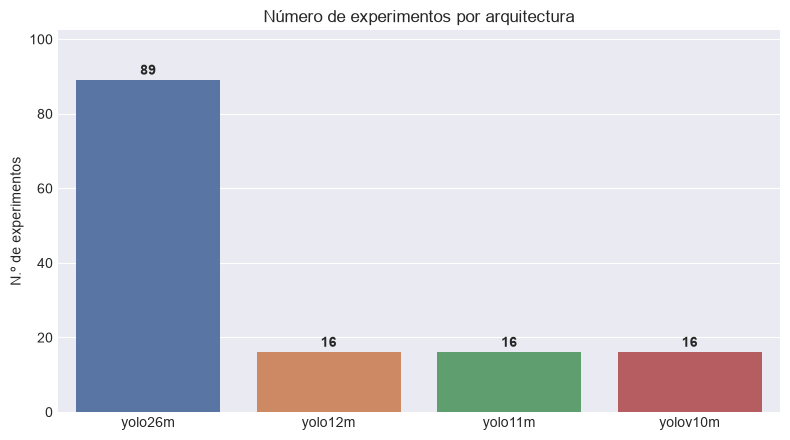

In [7]:
conteo = (
    DataUnion12["modelo"]
    .value_counts()
    .reindex(ORDEN_MODELOS)
    .rename_axis("Modelo")
    .reset_index(name="Experimentos")
)
conteo["% del total"] = (conteo["Experimentos"] / len(DataUnion12) * 100).round(1)
conteo["Mejor mAP50-95"] = (
    conteo["Modelo"].map(DataUnion12.groupby("modelo")["map50_95"].max()).round(4)
)
display(conteo)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(
    data=conteo, x="Modelo", y="Experimentos",
    hue="Modelo", palette=COLORES_MODELO, order=ORDEN_MODELOS,
    legend=False, ax=ax,
)
for i, v in enumerate(conteo["Experimentos"]):
    ax.text(i, v + 1.5, str(v), ha="center", fontweight="bold")
ax.set_title("Número de experimentos por arquitectura")
ax.set_xlabel("")
ax.set_ylabel("N.º de experimentos")
ax.set_ylim(0, conteo["Experimentos"].max() * 1.15)
plt.tight_layout()
plt.show()

## 2. Cobertura de hiperparámetros por arquitectura

La comparación entre arquitecturas solo es válida si todas fueron evaluadas bajo condiciones similares. Esta sección muestra qué combinaciones de épocas, batch, learning rate y optimizador se probaron en cada caso.

,experimentos,epocas,batch,learning_rate,optimizador
Arquitectura,,,,,
yolo26m,89,"50, 100, 101, 102, 103, 105, 150, 200","6, 8, 10, 12","0.001, 0.01, 0.1, 0.5","AdamW, SGD"
yolo12m,16,"101, 106, 150, 200","6, 8","0.1, 0.5","AdamW, SGD"
yolo11m,16,"101, 102, 150, 171, 200","6, 8","0.1, 0.5","AdamW, SGD"
yolov10m,16,"101, 105, 106, 150, 200","6, 8","0.1, 0.5","AdamW, SGD"


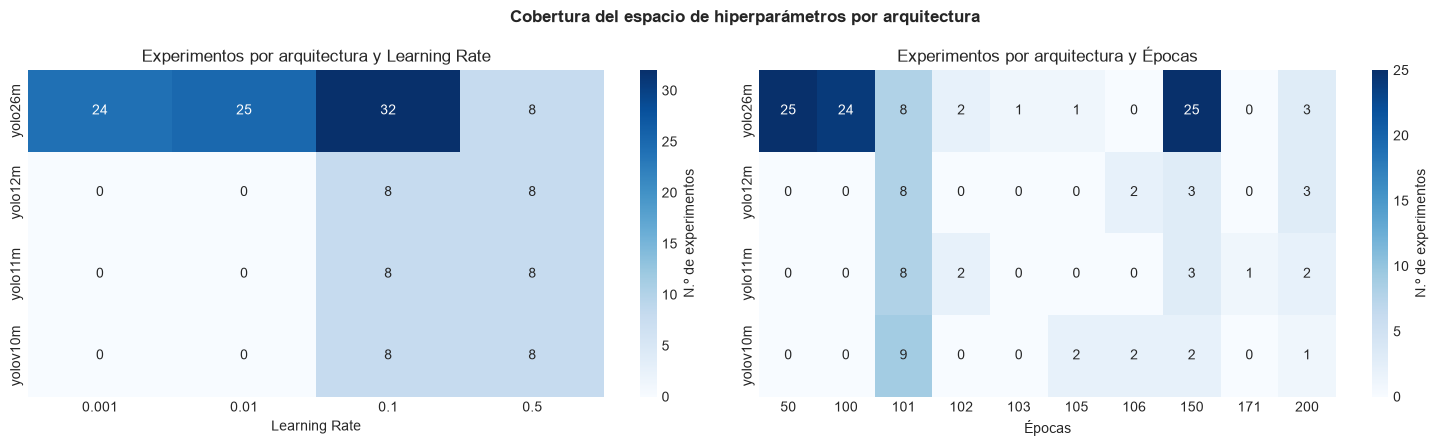

In [8]:
def lista_valores(serie):
    return ", ".join(str(v) for v in sorted(serie.dropna().unique()))

cobertura = (
    DataUnion12.groupby("modelo")
    .agg(
        experimentos=("map50_95", "size"),
        epocas=("epocas_fin", lista_valores),
        batch=("batch", lista_valores),
        learning_rate=("learning_rate", lista_valores),
        optimizador=("optimizer", lista_valores),
    )
    .reindex(ORDEN_MODELOS)
)
cobertura.index.name = "Arquitectura"
display(cobertura)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, col, titulo in [
    (axes[0], "learning_rate", "Learning Rate"),
    (axes[1], "epocas_fin", "Épocas"),
]:
    pivot = (
        DataUnion12.pivot_table(
            index="modelo", columns=col, values="map50_95", aggfunc="count"
        )
        .reindex(ORDEN_MODELOS)
        .fillna(0)
        .astype(int)
    )
    sns.heatmap(
        pivot, annot=True, fmt="d", cmap="Blues", ax=ax,
        cbar_kws={"label": "N.º de experimentos"},
    )
    ax.set_title(f"Experimentos por arquitectura y {titulo}")
    ax.set_xlabel(titulo)
    ax.set_ylabel("")

fig.suptitle(
    "Cobertura del espacio de hiperparámetros por arquitectura",
    fontweight="bold",
)
plt.tight_layout()
plt.show()

**Lectura:** `yolo26m` explora learning rates de `0.001`, `0.01` y `0.1`, mientras que `yolo12m`, `yolo11m` y `yolov10m` solo se probaron con `0.1` y `0.5`. Esta asimetría es clave: los valores altos de LR degradan el entrenamiento y penalizan la media de las tres arquitecturas nuevas.

<br />

Esto también se debe a que se exploró más opciones dentro del yolo26, dado que es la versión más reciente, y menos usada aún en publicaciones.

## 3. Estadísticas descriptivas por arquitectura

Se resumen las métricas de todas las configuraciones de cada arquitectura. La **media** describe el comportamiento del espacio explorado; el **máximo** refleja el mejor resultado alcanzable con el tuning realizado.

In [9]:
metricas = ["map50", "map50_95", "precision", "recall", "tiempo_minutos"]
resumen = (
    DataUnion12.groupby("modelo")[metricas]
    .agg(["count", "mean", "std", "min", "median", "max"])
    .reindex(ORDEN_MODELOS)
)
resumen.index.name = "Arquitectura"
display(resumen.round(4))

tabla_medias = DataUnion12.groupby("modelo")[metricas].mean().reindex(ORDEN_MODELOS)
tabla_medias.index.name = "Arquitectura"
display(
    tabla_medias.round(4)
    .style.background_gradient(cmap="YlGnBu", axis=0)
    .format("{:.4f}")
)

map50                                         map50_95                                         precision                                         recall                                          \
             count    mean     std     min  median     max    count    mean     std     min  median     max     count    mean     std     min  median     max  count    mean     std     min  median     max   
Arquitectura                                                                                                                                                                                                   
yolo26m         89  0.3575  0.2321  0.0028  0.4236  0.6359       89  0.1170  0.0827  0.0009  0.1288  0.2250        89  0.4070  0.2348  0.0287  0.4884  0.6801     89  0.4431  0.1876  0.0749  0.5186  0.6571   
yolo12m         16  0.0760  0.0927  0.0080  0.0239  0.2760       16  0.0180  0.0224  0.0020  0.0046  0.0707        16  0.1221  0.0903  0.0480  0.0749  0.3406     16  0.2426  0.1472  0.1250  0.1581  0.4826   
yolo11m         16  0.0656  0.0769  0.0124  0.0174  0.2267       16  0.0155  0.0182  0.0029  0.0038  0.0557        16  0.1154  0.0636  0.0656  0.0755  0.2473     16  0.2739  0.1295  0.1711  0.1969  0.4946   
yolov10m        16  0.0605  0.0440  0.0331  0.0340  0.1855       16  0.0141  0.0098  0.0078  0.0080  0.0414        16  0.1252  0.0339  0.1038  0.1044  0.2194     16  0.3179  0.0674  0.2707  0.2721  0.4372   

             tiempo_minutos                                          
                      count    mean     std     min  median     max  
Arquitectura                                                         
yolo26m                  89  2.7126  1.2132  1.0256  2.5506  6.7721  
yolo12m                  16  2.8887  0.9400  1.9654  2.4843  4.9358  
yolo11m                  16  2.5485  0.8909  1.7221  2.1643  4.4981  
yolov10m                 16  2.5481  0.7190  1.9225  2.2906  4.5048

,map50,map50_95,precision,recall,tiempo_minutos
Arquitectura,,,,,
yolo26m,0.3575,0.1170,0.4070,0.4431,2.7126
yolo12m,0.0760,0.0180,0.1221,0.2426,2.8887
yolo11m,0.0656,0.0155,0.1154,0.2739,2.5485
yolov10m,0.0605,0.0141,0.1252,0.3179,2.5481


### 3.1 Mejor configuración de cada arquitectura

Para cada arquitectura se selecciona la corrida con mayor `map50_95`. Esta tabla es la base de la comparación "mejor contra mejor".

In [10]:
idx_mejor = DataUnion12.groupby("modelo")["map50_95"].idxmax()
mejores = (
    DataUnion12.loc[idx_mejor]
    .sort_values("map50_95", ascending=False)
    .reset_index(drop=True)
)
mejores.insert(0, "Rank", np.arange(1, len(mejores) + 1))

tabla_mejores = mejores[[
    "Rank", "modelo", "epocas_fin", "batch", "learning_rate", "optimizer",
    "map50", "map50_95", "precision", "recall", "tiempo_minutos",
]].rename(columns={
    "modelo": "Arquitectura",
    "epocas_fin": "Épocas",
    "batch": "Batch",
    "learning_rate": "LR",
    "optimizer": "Optimizador",
    "map50": "mAP50",
    "map50_95": "mAP50-95",
    "precision": "Precisión",
    "recall": "Recall",
    "tiempo_minutos": "Tiempo (min)",
})

display(
    tabla_mejores.style
    .background_gradient(subset=["mAP50-95"], cmap="YlGn")
    .format({
        "mAP50": "{:.4f}", "mAP50-95": "{:.4f}",
        "Precisión": "{:.4f}", "Recall": "{:.4f}",
        "Tiempo (min)": "{:.2f}",
    })
)

,Rank,Arquitectura,Épocas,Batch,LR,Optimizador,mAP50,mAP50-95,Precisión,Recall,Tiempo (min)
0,1,yolo26m,150,8,0.010000,SGD,0.6293,0.2250,0.6603,0.6524,3.18
1,2,yolo12m,200,8,0.100000,SGD,0.2761,0.0707,0.3406,0.4164,3.66
2,3,yolo11m,200,6,0.100000,AdamW,0.2267,0.0557,0.2473,0.4806,4.50
3,4,yolov10m,200,8,0.100000,AdamW,0.1855,0.0414,0.2194,0.4372,4.50


## 4. Comparación visual de métricas

### 4.1 Media, dispersión y máximo por arquitectura

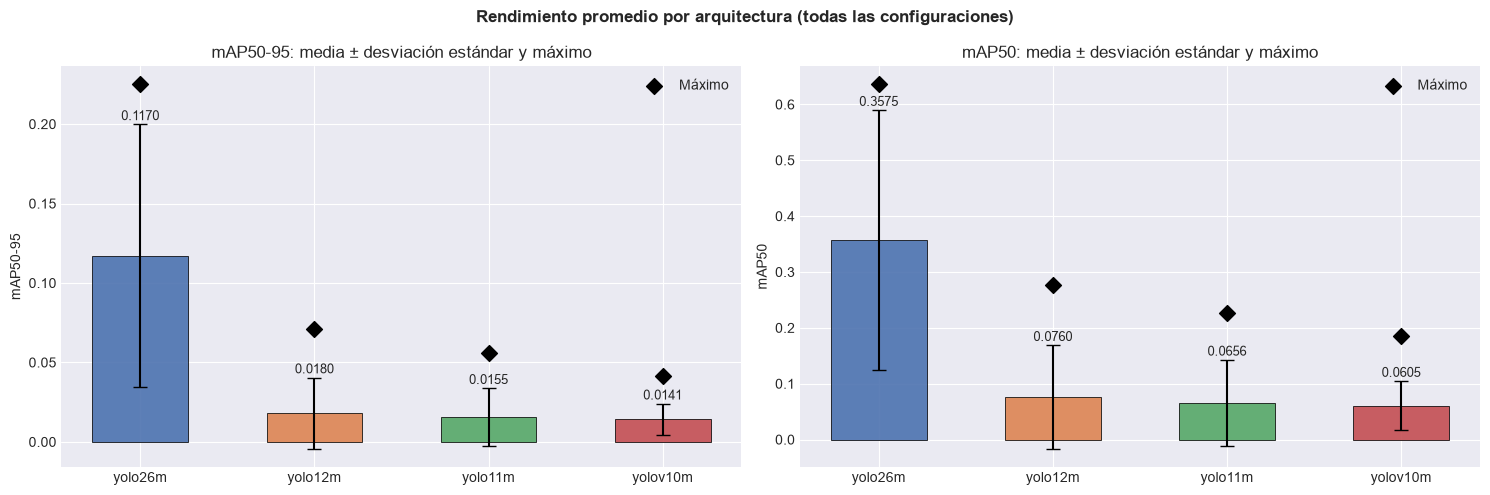

In [11]:
stats_modelo = (
    DataUnion12.groupby("modelo")[["map50", "map50_95"]]
    .agg(["mean", "std", "max"])
    .reindex(ORDEN_MODELOS)
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
x = np.arange(len(ORDEN_MODELOS))

for ax, metrica, titulo in [
    (axes[0], "map50_95", "mAP50-95"),
    (axes[1], "map50", "mAP50"),
]:
    medias = stats_modelo[(metrica, "mean")]
    desv = stats_modelo[(metrica, "std")]
    maximos = stats_modelo[(metrica, "max")]

    ax.bar(
        x, medias, 0.55, yerr=desv, capsize=5,
        color=[COLORES_MODELO[m] for m in ORDEN_MODELOS],
        edgecolor="black", linewidth=0.6, alpha=0.9,
    )
    ax.scatter(x, maximos, marker="D", s=65, color="black", zorder=3, label="Máximo")

    for i, (media, desviacion) in enumerate(zip(medias, desv)):
        ax.text(
            i, media + desviacion + 0.012 * maximos.max(),
            f"{media:.4f}", ha="center", fontsize=9,
        )

    ax.set_xticks(x)
    ax.set_xticklabels(ORDEN_MODELOS)
    ax.set_ylabel(titulo)
    ax.set_title(f"{titulo}: media ± desviación estándar y máximo")
    ax.legend(loc="upper right")

fig.suptitle(
    "Rendimiento promedio por arquitectura (todas las configuraciones)",
    fontweight="bold",
)
plt.tight_layout()
plt.show()

### 4.2 Distribución de las cuatro métricas

Cada punto representa una configuración entrenada. Los boxplots permiten ver no solo el nivel promedio, sino también la **variabilidad** y los valores atípicos de cada arquitectura.

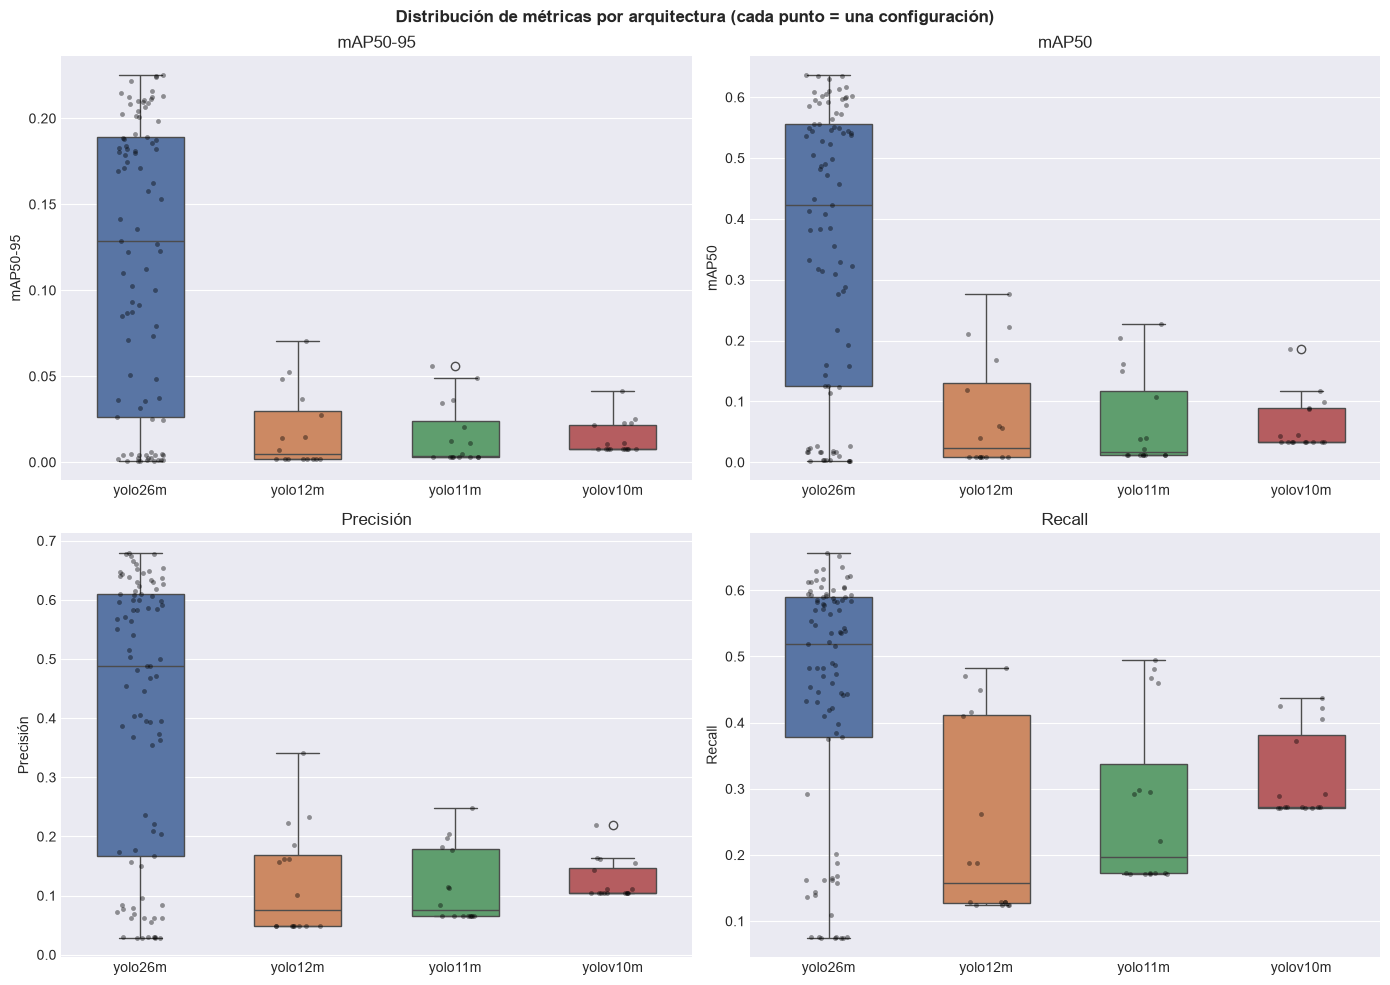

In [12]:
pares = [
    ("map50_95", "mAP50-95"),
    ("map50", "mAP50"),
    ("precision", "Precisión"),
    ("recall", "Recall"),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (col, titulo) in zip(axes.ravel(), pares):
    sns.boxplot(
        data=DataUnion12, x="modelo", y=col, order=ORDEN_MODELOS,
        hue="modelo", palette=COLORES_MODELO, legend=False,
        width=0.55, ax=ax,
    )
    sns.stripplot(
        data=DataUnion12, x="modelo", y=col, order=ORDEN_MODELOS,
        color="black", alpha=0.4, size=3.5, jitter=0.15, ax=ax,
    )
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.set_ylabel(titulo)

fig.suptitle(
    "Distribución de métricas por arquitectura (cada punto = una configuración)",
    fontweight="bold",
)
plt.tight_layout()
plt.show()

### 4.3 Top 3 configuraciones por arquitectura

Un ranking global estaría dominado por `yolo26m` (que tiene 89 corridas). Para comparar de forma más informativa se muestran las **tres mejores configuraciones de cada arquitectura**.

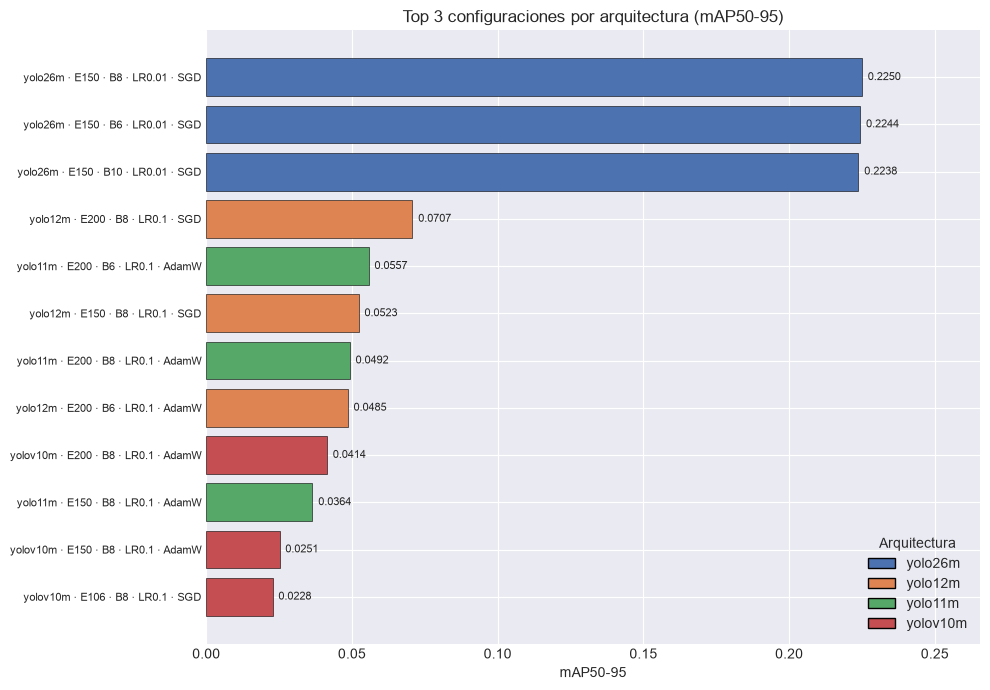

In [13]:
top3 = (
    DataUnion12.sort_values("map50_95", ascending=False)
    .groupby("modelo", group_keys=False)
    .head(3)
    .sort_values("map50_95", ascending=False)
    .copy()
)
top3["etiqueta"] = top3.apply(
    lambda r: (
        f"{r['modelo']} · E{int(r['epocas_fin'])} · B{int(r['batch'])}"
        f" · LR{r['learning_rate']} · {r['optimizer']}"
    ),
    axis=1,
)

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(
    range(len(top3)), top3["map50_95"],
    color=[COLORES_MODELO[m] for m in top3["modelo"]],
    edgecolor="black", linewidth=0.4,
)
ax.set_yticks(range(len(top3)))
ax.set_yticklabels(top3["etiqueta"], fontsize=8)
ax.invert_yaxis()
for i, v in enumerate(top3["map50_95"]):
    ax.text(v + 0.002, i, f"{v:.4f}", va="center", fontsize=8)
ax.set_xlabel("mAP50-95")
ax.set_title("Top 3 configuraciones por arquitectura (mAP50-95)")

handles = [
    Patch(facecolor=COLORES_MODELO[m], edgecolor="black", label=m)
    for m in ORDEN_MODELOS
]
ax.legend(handles=handles, title="Arquitectura", loc="lower right")
ax.set_xlim(0, top3["map50_95"].max() * 1.18)
plt.tight_layout()
plt.show()

## 5. Eficiencia computacional

Un modelo con mejor mAP no siempre es la mejor opción si requiere mucho más tiempo. Se analiza la relación entre **mAP50-95** y **tiempo de entrenamiento**, junto con la métrica de eficiencia `mAP50-95 por minuto`.

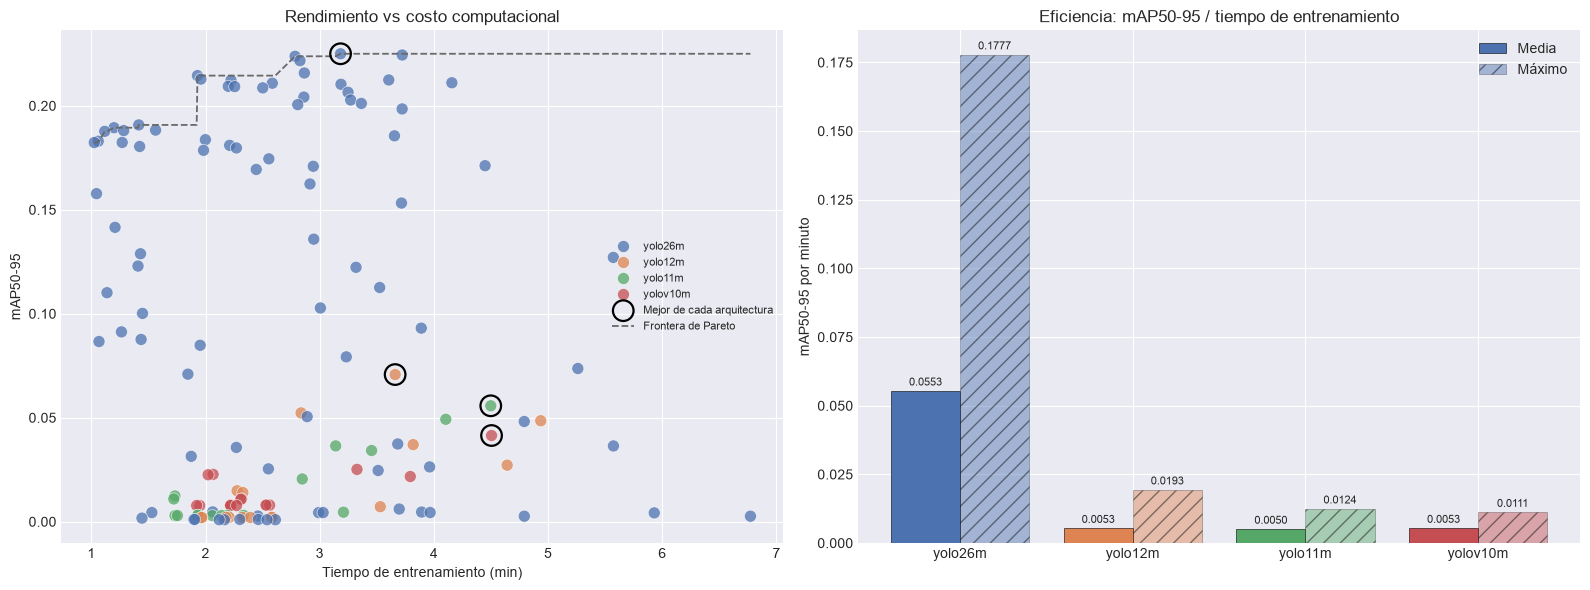

In [14]:
DataUnion12["map50_95_por_min"] = DataUnion12["map50_95"] / DataUnion12["tiempo_minutos"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Rendimiento vs tiempo ---
ax = axes[0]
sns.scatterplot(
    data=DataUnion12, x="tiempo_minutos", y="map50_95",
    hue="modelo", hue_order=ORDEN_MODELOS, palette=COLORES_MODELO,
    s=75, alpha=0.75, edgecolor="white", linewidth=0.5, ax=ax,
)
ax.scatter(
    mejores["tiempo_minutos"], mejores["map50_95"],
    s=220, facecolors="none", edgecolors="black", linewidth=1.6,
    label="Mejor de cada arquitectura", zorder=5,
)
pareto = DataUnion12.sort_values("tiempo_minutos")
ax.plot(
    pareto["tiempo_minutos"], pareto["map50_95"].cummax(),
    color="dimgray", ls="--", lw=1.3, label="Frontera de Pareto",
)
ax.set_xlabel("Tiempo de entrenamiento (min)")
ax.set_ylabel("mAP50-95")
ax.set_title("Rendimiento vs costo computacional")
ax.legend(fontsize=8)

# --- Eficiencia media y máxima ---
eff = (
    DataUnion12.groupby("modelo")["map50_95_por_min"]
    .agg(["mean", "max"])
    .reindex(ORDEN_MODELOS)
)
x = np.arange(len(ORDEN_MODELOS))
axes[1].bar(
    x - 0.2, eff["mean"], 0.4, label="Media",
    color=[COLORES_MODELO[m] for m in ORDEN_MODELOS],
    edgecolor="black", linewidth=0.4,
)
axes[1].bar(
    x + 0.2, eff["max"], 0.4, label="Máximo",
    color=[COLORES_MODELO[m] for m in ORDEN_MODELOS],
    edgecolor="black", linewidth=0.4, alpha=0.45, hatch="//",
)
for i, (media, maximo) in enumerate(zip(eff["mean"], eff["max"])):
    axes[1].text(i - 0.2, media + 0.002, f"{media:.4f}", ha="center", fontsize=8)
    axes[1].text(i + 0.2, maximo + 0.002, f"{maximo:.4f}", ha="center", fontsize=8)
axes[1].set_xticks(x)
axes[1].set_xticklabels(ORDEN_MODELOS)
axes[1].set_ylabel("mAP50-95 por minuto")
axes[1].set_title("Eficiencia: mAP50-95 / tiempo de entrenamiento")
axes[1].legend()

plt.tight_layout()
plt.show()

## 6. Efecto de los hiperparámetros dentro de cada arquitectura

Los siguientes mapas de calor muestran el **mAP50-95 medio** para cada combinación de arquitectura e hiperparámetro. Las celdas vacías indican combinaciones no evaluadas.

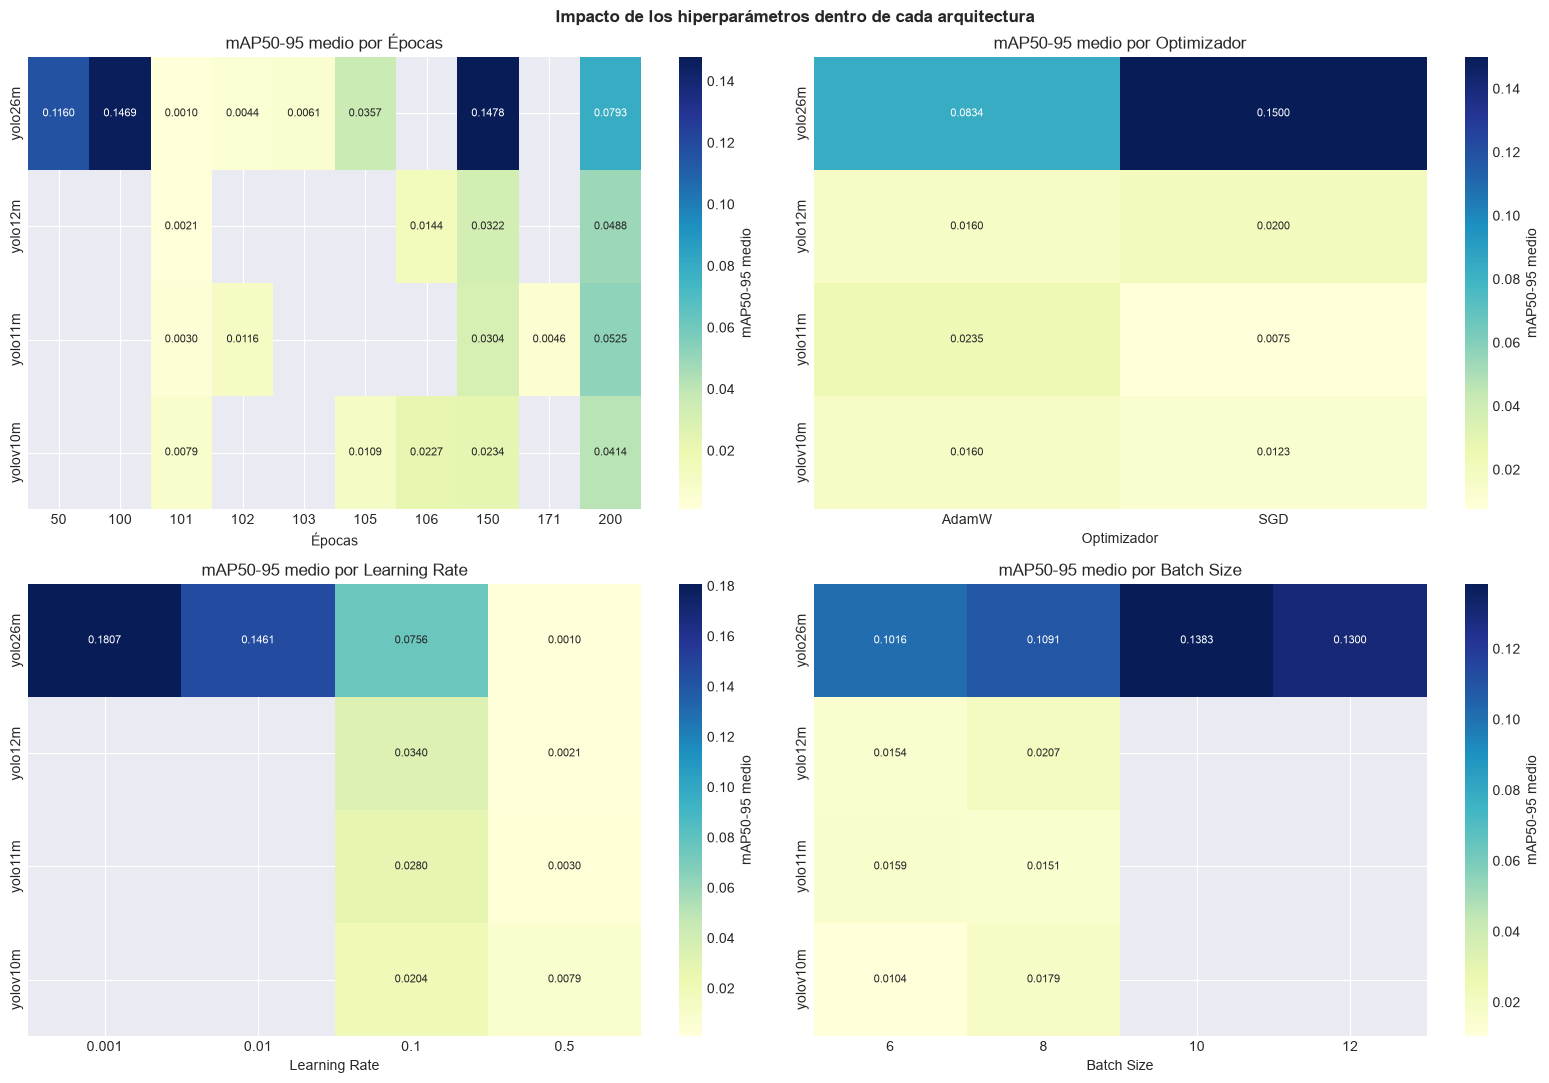

In [15]:
configuraciones = [
    ("epocas_fin", "Épocas"),
    ("optimizer", "Optimizador"),
    ("learning_rate", "Learning Rate"),
    ("batch", "Batch Size"),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, (col, etiqueta) in zip(axes.ravel(), configuraciones):
    pivot = (
        DataUnion12.pivot_table(
            index="modelo", columns=col, values="map50_95", aggfunc="mean"
        )
        .reindex(ORDEN_MODELOS)
    )
    sns.heatmap(
        pivot, annot=True, fmt=".4f", cmap="YlGnBu", ax=ax,
        mask=pivot.isna(), annot_kws={"fontsize": 8},
        cbar_kws={"label": "mAP50-95 medio"},
    )
    ax.set_title(f"mAP50-95 medio por {etiqueta}")
    ax.set_xlabel(etiqueta)
    ax.set_ylabel("")

fig.suptitle(
    "Impacto de los hiperparámetros dentro de cada arquitectura",
    fontweight="bold",
)
plt.tight_layout()
plt.show()

### 6.1 Efecto del número de épocas

Las cuatro arquitecturas solo comparten las épocas `150` y `200`; `50` y `100` se exploraron únicamente en `yolo26m`, y las corridas de `101–106` son pruebas interrumpidas. Por eso la comparación se limita a `150` y `200` épocas.

> **Nota:** la cobertura no es idéntica. En `yolo26m` las corridas de 200 épocas solo usan `LR=0.1`, mientras que las de 150 incluyen `LR=0.001`, `0.01` y `0.1`. La caída en 200 refleja esa diferencia de cobertura, no necesariamente sobreajuste.

count    mean     max
Arquitectura Épocas                       
yolo11m      150         3  0.0304  0.0364
             200         2  0.0525  0.0557
yolo12m      150         3  0.0322  0.0523
             200         3  0.0488  0.0707
yolo26m      150        25  0.1478  0.2250
             200         3  0.0793  0.1532
yolov10m     150         2  0.0234  0.0251
             200         1  0.0414  0.0414

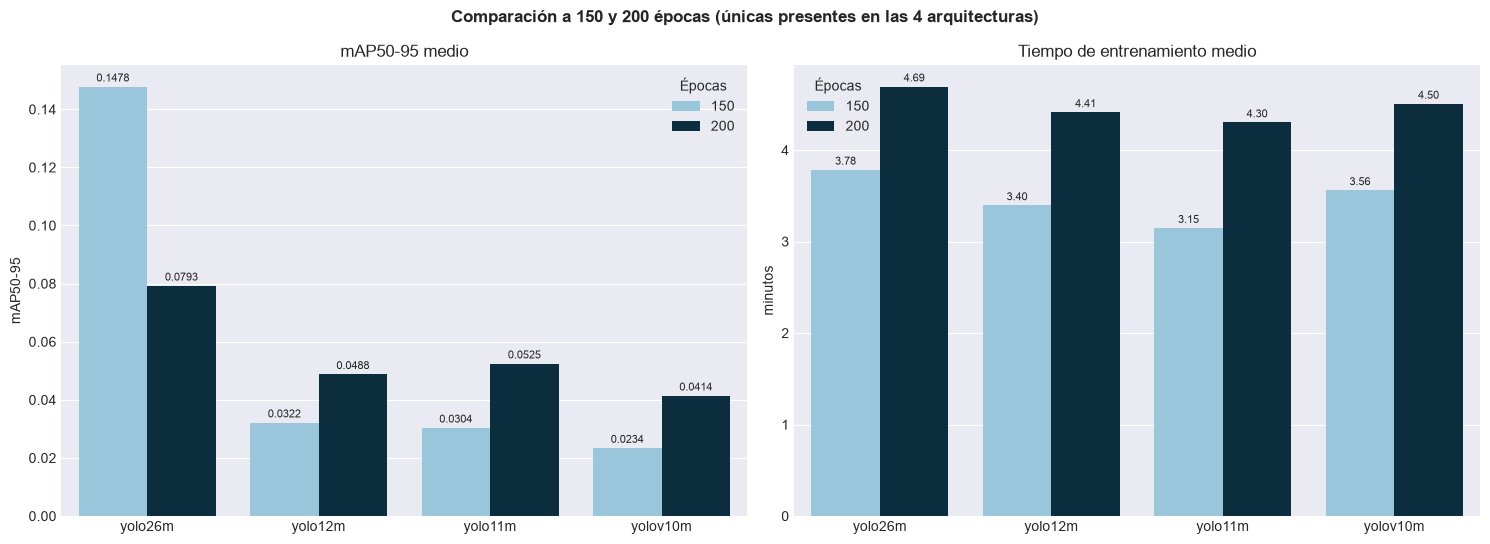

In [16]:
df_epocas = DataUnion12[DataUnion12["epocas_fin"].isin([150, 200])].copy()

tabla_epocas = (
    df_epocas.groupby(["modelo", "epocas_fin"])["map50_95"]
    .agg(["count", "mean", "max"])
    .round(4)
)
tabla_epocas.index.names = ["Arquitectura", "Épocas"]
display(tabla_epocas)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, metrica, titulo, unidad in [
    (axes[0], "map50_95", "mAP50-95 medio", "mAP50-95"),
    (axes[1], "tiempo_minutos", "Tiempo de entrenamiento medio", "minutos"),
]:
    sns.barplot(
        data=df_epocas, x="modelo", y=metrica, hue="epocas_fin",
        order=ORDEN_MODELOS, palette=["#8ECAE6", "#023047"],
        errorbar=None, ax=ax,
    )
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.4f" if metrica == "map50_95" else "%.2f",
            fontsize=8, padding=2,
        )
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.set_ylabel(unidad)
    ax.legend(title="Épocas")

fig.suptitle(
    "Comparación a 150 y 200 épocas (únicas presentes en las 4 arquitecturas)",
    fontweight="bold",
)
plt.tight_layout()
plt.show()

## 7. Ranking completo y tabla ejecutiva

### 7.1 Top 25 configuraciones globales

El color de cada fila identifica la arquitectura. El degradado resalta el valor de `mAP50-95`.

In [17]:
df_ranking = (
    DataUnion12.sort_values("map50_95", ascending=False)
    .head(25)
    .copy()
)
df_ranking.insert(0, "Rank", np.arange(1, len(df_ranking) + 1))
df_ranking = df_ranking[[
    "Rank", "modelo", "epocas_fin", "batch", "learning_rate", "optimizer",
    "map50", "map50_95", "precision", "recall", "tiempo_minutos",
]].rename(columns={
    "modelo": "Arquitectura",
    "epocas_fin": "Épocas",
    "batch": "Batch",
    "learning_rate": "LR",
    "optimizer": "Optimizador",
    "map50": "mAP50",
    "map50_95": "mAP50-95",
    "precision": "Precisión",
    "recall": "Recall",
    "tiempo_minutos": "Tiempo (min)",
})

def color_arquitectura(fila):
    color = COLORES_MODELO.get(fila["Arquitectura"], "#FFFFFF")
    return [f"background-color: {color}33"] * len(fila)

display(
    df_ranking.style
    .apply(color_arquitectura, axis=1)
    .background_gradient(subset=["mAP50-95"], cmap="YlGn")
    .format({
        "mAP50": "{:.4f}", "mAP50-95": "{:.4f}",
        "Precisión": "{:.4f}", "Recall": "{:.4f}",
        "Tiempo (min)": "{:.2f}",
    })
)

,Rank,Arquitectura,Épocas,Batch,LR,Optimizador,mAP50,mAP50-95,Precisión,Recall,Tiempo (min)
1,1,yolo26m,150,8,0.010000,SGD,0.6293,0.2250,0.6603,0.6524,3.18
2,2,yolo26m,150,6,0.010000,SGD,0.6359,0.2244,0.6801,0.6317,3.72
3,3,yolo26m,150,10,0.010000,SGD,0.6351,0.2238,0.6740,0.6571,2.78
4,4,yolo26m,150,12,0.010000,SGD,0.6347,0.2217,0.6773,0.6297,2.83
5,5,yolo26m,100,6,0.001000,AdamW,0.6162,0.2157,0.6459,0.6048,2.87
6,6,yolo26m,100,10,0.010000,SGD,0.6100,0.2145,0.6474,0.6177,1.93
7,7,yolo26m,100,12,0.010000,SGD,0.6135,0.2128,0.6492,0.6350,1.96
8,8,yolo26m,150,8,0.001000,AdamW,0.6058,0.2124,0.6329,0.6222,3.60
9,9,yolo26m,100,8,0.010000,SGD,0.6090,0.2122,0.6444,0.6156,2.22
10,10,yolo26m,150,6,0.001000,AdamW,0.6013,0.2110,0.6263,0.6129,4.16


### 7.2 Tabla ejecutiva por arquitectura

In [18]:
baseline_map50 = float(DataBase11.loc[0, "map50"])
baseline_map50_95 = float(DataBase11.loc[0, "map50_95"])

mejores_idx = mejores.set_index("modelo")
resumen_ejecutivo = pd.DataFrame(index=ORDEN_MODELOS)
resumen_ejecutivo.index.name = "Arquitectura"
resumen_ejecutivo["Experimentos"] = DataUnion12.groupby("modelo").size()
resumen_ejecutivo["mAP50-95 medio"] = DataUnion12.groupby("modelo")["map50_95"].mean()
resumen_ejecutivo["mAP50-95 máximo"] = mejores_idx["map50_95"]
resumen_ejecutivo["mAP50 (mejor)"] = mejores_idx["map50"]
resumen_ejecutivo["Precisión (mejor)"] = mejores_idx["precision"]
resumen_ejecutivo["Recall (mejor)"] = mejores_idx["recall"]
resumen_ejecutivo["Mejor configuración"] = mejores_idx.apply(
    lambda r: (
        f"E{int(r['epocas_fin'])} · B{int(r['batch'])}"
        f" · LR{r['learning_rate']} · {r['optimizer']}"
    ),
    axis=1,
)
resumen_ejecutivo["Tiempo mejor (min)"] = mejores_idx["tiempo_minutos"]
resumen_ejecutivo["mAP50-95/min (mejor)"] = (
    mejores_idx["map50_95"] / mejores_idx["tiempo_minutos"]
)
resumen_ejecutivo["Δ vs baseline (%)"] = (
    (mejores_idx["map50_95"] / baseline_map50_95 - 1) * 100
)
resumen_ejecutivo = resumen_ejecutivo.sort_values(
    "mAP50-95 máximo", ascending=False
)

display(
    resumen_ejecutivo.style
    .background_gradient(subset=["mAP50-95 medio", "mAP50-95 máximo"], cmap="YlGn")
    .background_gradient(subset=["Δ vs baseline (%)"], cmap="RdYlGn")
    .format({
        "Experimentos": "{:.0f}",
        "mAP50-95 medio": "{:.4f}",
        "mAP50-95 máximo": "{:.4f}",
        "mAP50 (mejor)": "{:.4f}",
        "Precisión (mejor)": "{:.4f}",
        "Recall (mejor)": "{:.4f}",
        "Tiempo mejor (min)": "{:.2f}",
        "mAP50-95/min (mejor)": "{:.4f}",
        "Δ vs baseline (%)": "{:+.1f}%",
    })
)

,Experimentos,mAP50-95 medio,mAP50-95 máximo,mAP50 (mejor),Precisión (mejor),Recall (mejor),Mejor configuración,Tiempo mejor (min),mAP50-95/min (mejor),Δ vs baseline (%)
Arquitectura,,,,,,,,,,
yolo26m,89,0.1170,0.2250,0.6293,0.6603,0.6524,E150 · B8 · LR0.01 · SGD,3.18,0.0707,+23.4%
yolo12m,16,0.0180,0.0707,0.2761,0.3406,0.4164,E200 · B8 · LR0.1 · SGD,3.66,0.0193,-61.2%
yolo11m,16,0.0155,0.0557,0.2267,0.2473,0.4806,E200 · B6 · LR0.1 · AdamW,4.50,0.0124,-69.4%
yolov10m,16,0.0141,0.0414,0.1855,0.2194,0.4372,E200 · B8 · LR0.1 · AdamW,4.50,0.0092,-77.3%


## 8. Conclusiones

1. **Mejor resultado global — `yolo26m`.** Su mejor corrida (150 épocas, batch 8, `LR=0.01`, SGD) alcanza **mAP50-95 = 0.2250** y **mAP50 = 0.6293**, un **+23.4%** y **+13.2%** respecto al baseline (0.1823 y 0.5560). Es la única arquitectura que supera al baseline.

2. **Las demás arquitecturas quedan muy por debajo del baseline** en su mejor corrida: `yolo12m` 0.0707 (−61.2%), `yolo11m` 0.0557 (−69.4%) y `yolov10m` 0.0414 (−77.3%). Sin embargo, todas se evaluaron solo con `LR=0.1` o `0.5`, valores demasiado altos para este dataset.

3. **El learning rate es el factor dominante.** Las corridas con `LR=0.5` colapsan a `mAP50-95 ≈ 0.001–0.008` en todas las arquitecturas, mientras que las de `LR=0.01` (solo probadas en `yolo26m`) producen los mejores resultados. La arquitectura importa, pero el presupuesto de tuning importa más.

4. **Eficiencia.** `yolo26m` lidera en `mAP50-95` por minuto (media 0.0553; máximo 0.1777), de nuevo por las configuraciones con LR bajo. En la receta comparable los tiempos medios son similares (3.8–4.7 min), sin una ventaja clara de costo entre arquitecturas.
